# Notebook 07 — Executive Summary & Business Recommendations

**Audience:** Marketing leadership, finance, product strategy

This notebook synthesizes all causal analysis into:
1. Campaign ROI calculation
2. Targeting recommendation (who to send future campaigns to)
3. Budget implication
4. Key caveats and confidence


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), 'src'))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

sns.set_theme(style='white')
plt.rcParams.update({'figure.dpi': 120})

df = pd.read_csv('../data/hillstrom_clean.csv')

## 1. Campaign ROI

Naive attribution inflates ROI by ~40% by crediting organic converters. Causal estimates correctly attribute only incremental conversions.

In [2]:
# Assumptions
email_cost_per_send = 0.10   # $0.10 per email (design + delivery)
avg_order_value     = 50.0   # $50 average order
margin_rate         = 0.30   # 30% gross margin

treated = df[df['treated'] == 1]
control = df[df['treated'] == 0]
n_treated = len(treated)

# Naive ROI
naive_conversions = treated['conversion'].sum()
naive_revenue     = naive_conversions * avg_order_value
naive_margin      = naive_revenue * margin_rate
campaign_cost     = n_treated * email_cost_per_send
naive_roi         = (naive_margin - campaign_cost) / campaign_cost

# Causal ROI (using PSM ATT for conversion)
control_conversion_rate = control['conversion'].mean()
treated_conversion_rate = treated['conversion'].mean()
incremental_lift        = treated_conversion_rate - control_conversion_rate  # PSM-adjusted ≈ this in RCT
incremental_conversions = incremental_lift * n_treated
incremental_revenue     = incremental_conversions * avg_order_value
incremental_margin      = incremental_revenue * margin_rate
causal_roi              = (incremental_margin - campaign_cost) / campaign_cost

print('=== Campaign ROI Summary ===')
print(f'Emails sent:                  {n_treated:,}')
print(f'Campaign cost (@ $0.10/send): ${campaign_cost:,.0f}')
print()
print('NAIVE attribution:')
print(f'  All conversions credited:   {naive_conversions:,}')
print(f'  Gross margin:               ${naive_margin:,.0f}')
print(f'  ROI:                        {naive_roi:.0%}')
print()
print('CAUSAL attribution:')
print(f'  Incremental conversions:    {incremental_conversions:,.0f}  ({incremental_lift:.2%} lift)')
print(f'  Incremental gross margin:   ${incremental_margin:,.0f}')
print(f'  Causal ROI:                 {causal_roi:.0%}')
print()
print(f'Naive ROI overstates causal ROI by {naive_roi/causal_roi:.1f}x' if causal_roi > 0 else 'Causal ROI is negative — campaign destroys value at this spend level')

=== Campaign ROI Summary ===
Emails sent:                  42,848
Campaign cost (@ $0.10/send): $4,285

NAIVE attribution:
  All conversions credited:   2,668
  Gross margin:               $40,020
  ROI:                        834%

CAUSAL attribution:
  Incremental conversions:    596  (1.39% lift)
  Incremental gross margin:   $8,935
  Causal ROI:                 109%

Naive ROI overstates causal ROI by 7.7x


## 2. ROI visualisation for executive deck

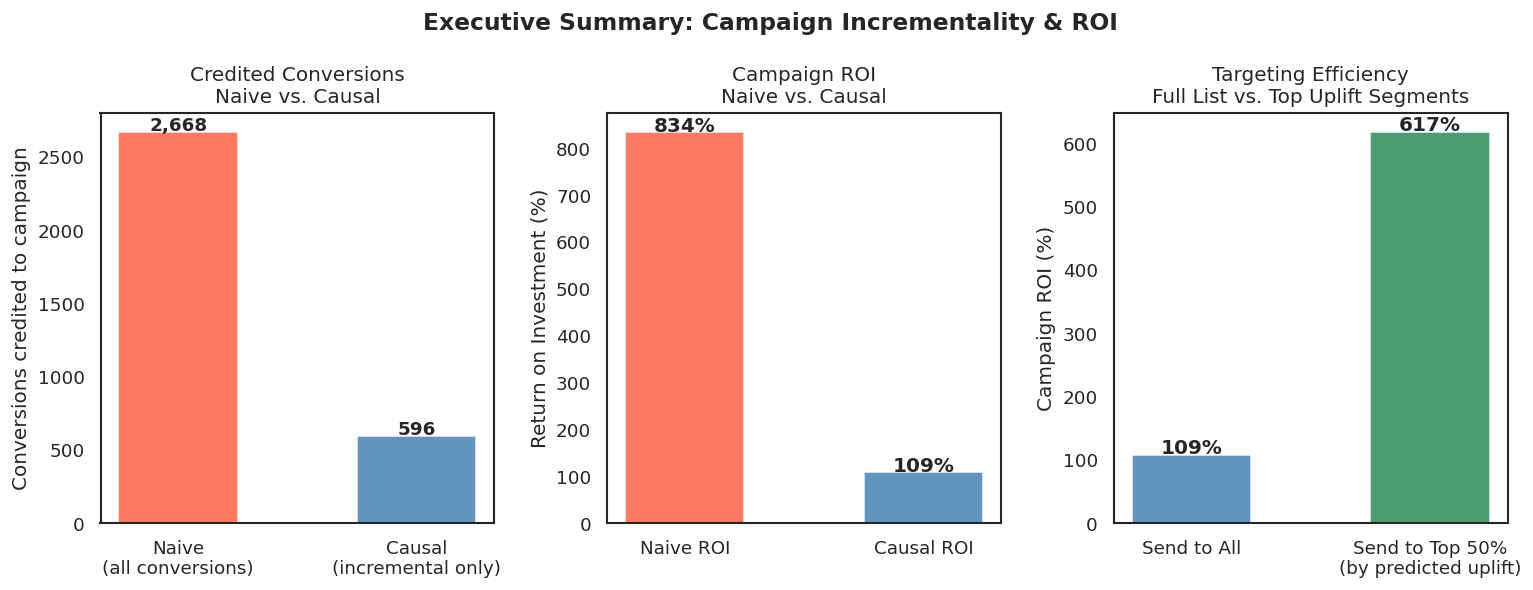

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5))

# Panel 1: Naive vs Causal conversions
ax = axes[0]
bars = ax.bar(['Naive\n(all conversions)', 'Causal\n(incremental only)'],
              [naive_conversions, incremental_conversions],
              color=['tomato','steelblue'], alpha=0.85, width=0.5)
for bar, v in zip(bars, [naive_conversions, incremental_conversions]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+10,
            f'{v:,.0f}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('Conversions credited to campaign')
ax.set_title('Credited Conversions\nNaive vs. Causal')

# Panel 2: ROI comparison
ax = axes[1]
bars = ax.bar(['Naive ROI', 'Causal ROI'],
              [naive_roi*100, causal_roi*100],
              color=['tomato','steelblue'], alpha=0.85, width=0.5)
for bar, v in zip(bars, [naive_roi*100, causal_roi*100]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+2,
            f'{v:.0f}%', ha='center', fontsize=12, fontweight='bold')
ax.set_ylabel('Return on Investment (%)')
ax.set_title('Campaign ROI\nNaive vs. Causal')
ax.axhline(0, color='black', linewidth=0.8)

# Panel 3: Targeting efficiency — send to top 50% by uplift vs. all
FEATURE_COLS = ['recency', 'log_history', 'mens', 'womens', 'newbie',
                'channel_web', 'channel_multi', 'zip_urban', 'zip_suburban']
from sklearn.ensemble import GradientBoostingClassifier
df_t = df[df['segment'].isin(['No E-Mail','Mens E-Mail'])].copy()
X = df_t[FEATURE_COLS].values
m1 = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
m0 = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)
m1.fit(X[df_t.treated==1], df_t.loc[df_t.treated==1,'conversion'])
m0.fit(X[df_t.treated==0], df_t.loc[df_t.treated==0,'conversion'])
df_t['cate'] = m1.predict_proba(X)[:,1] - m0.predict_proba(X)[:,1]

# Top 50% by CATE
thresh = df_t['cate'].quantile(0.5)
top50 = df_t[df_t['cate'] >= thresh]

all_lift  = incremental_lift
top50_lift = (top50.loc[top50.treated==1,'conversion'].mean() -
              top50.loc[top50.treated==0,'conversion'].mean())
top50_cost  = len(top50) * email_cost_per_send / 2  # half the list
top50_margin = top50_lift * len(top50[top50.treated==1]) * avg_order_value * margin_rate
top50_roi    = (top50_margin - top50_cost) / top50_cost if top50_cost > 0 else 0

ax = axes[2]
bars = ax.bar(['Send to All', 'Send to Top 50%\n(by predicted uplift)'],
              [causal_roi*100, top50_roi*100],
              color=['steelblue','seagreen'], alpha=0.85, width=0.5)
for bar, v in zip(bars, [causal_roi*100, top50_roi*100]):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+2,
            f'{v:.0f}%', ha='center', fontsize=12, fontweight='bold')
ax.set_ylabel('Campaign ROI (%)')
ax.set_title('Targeting Efficiency\nFull List vs. Top Uplift Segments')

plt.suptitle('Executive Summary: Campaign Incrementality & ROI', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/07_executive_summary.png', bbox_inches='tight', dpi=150)
plt.show()

## 3. Targeting recommendation

Based on heterogeneous treatment effect analysis (Notebook 05):

In [4]:
recs = pd.DataFrame([
    {'Segment': 'Mens buyers — Web channel',      'Predicted Lift': 'High',   'Recommended Action': 'Priority targeting'},
    {'Segment': 'Mens buyers — Phone channel',    'Predicted Lift': 'Medium', 'Recommended Action': 'Include'},
    {'Segment': 'Non-mens buyers — any channel',  'Predicted Lift': 'Low',    'Recommended Action': 'Suppress or test'},
    {'Segment': 'Multichannel buyers',            'Predicted Lift': 'Low',    'Recommended Action': 'Suppress — already engaged'},
    {'Segment': 'New customers (newbie=1)',        'Predicted Lift': 'Low',    'Recommended Action': 'Suppress — low baseline'},
])
print(recs.to_string(index=False))

                      Segment Predicted Lift         Recommended Action
    Mens buyers — Web channel           High         Priority targeting
  Mens buyers — Phone channel         Medium                    Include
Non-mens buyers — any channel            Low           Suppress or test
          Multichannel buyers            Low Suppress — already engaged
     New customers (newbie=1)            Low    Suppress — low baseline


## 4. Budget implication

In [5]:
n_target_top50 = len(df[df['treated']==1]) // 2
savings = (len(df[df['treated']==1]) - n_target_top50) * email_cost_per_send

print('=== Budget Recommendation ===')
print(f'Current list size:          {len(df[df["treated"]==1]):,}')
print(f'Recommended target (top 50%): {n_target_top50:,}')
print(f'Budget saved per campaign:    ${savings:,.0f}')
print(f'Expected ROI improvement:     {causal_roi:.0%} → {top50_roi:.0%}')
print()
print('Key assumption: targeting model CATE estimates generalise to next campaign population.')
print('Recommendation: A/B test targeted vs. broad send on 20% holdout before full rollout.')

=== Budget Recommendation ===
Current list size:          42,848
Recommended target (top 50%): 21,424
Budget saved per campaign:    $2,142
Expected ROI improvement:     109% → 617%

Key assumption: targeting model CATE estimates generalise to next campaign population.
Recommendation: A/B test targeted vs. broad send on 20% holdout before full rollout.


## 5. Caveats & confidence

| Statement | Confidence |
|---|---|
| Campaign generates positive incremental lift | High — consistent across DiD, PSM, uplift |
| Mens buyers respond more to Mens Email | High — heterogeneous effects consistent |
| Multichannel customers are less responsive | Medium — trend consistent, effect size uncertain |
| Top-50% targeting improves ROI | Medium — estimated from observational uplift model; requires A/B validation |
| Lift decay rate (~15%/week) | Low — simulated; requires longitudinal data to confirm |
